In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.naive_bayes import BernoulliNB
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score
from sklearn import metrics
#from sklearn.cross_validation import train_test_split
import os,sys
from scipy import stats

from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix



In [ ]:
from google.colab import files
uploaded = files.upload()

Saving train_data_2.csv to train_data_2.csv


In [ ]:
DF = pd.read_csv("train_data_2.csv") #data frame
DF

,date,positive_score,negative_score,neutral_score,overall_sentiment_score,company,close_label_day_5
0,2016-01-04,0.133743,0.396983,0.469274,-0.263240,1,0
1,2016-01-05,0.091346,0.131160,0.777493,-0.039814,1,0
2,2016-01-06,0.071314,0.213325,0.715361,-0.142010,1,0
3,2016-01-07,0.241937,0.159119,0.598944,0.082819,1,0
4,2016-01-08,0.179590,0.048467,0.771943,0.131123,1,0
...,...,...,...,...,...,...,...
1607,2019-05-22,0.139949,0.415843,0.444207,-0.275894,2,0
1608,2019-05-23,0.227064,0.239759,0.533178,-0.012695,2,0
1609,2019-05-24,0.121350,0.107019,0.771631,0.014330,2,0
1610,2019-05-28,0.149207,0.293771,0.557022,-0.144564,2,0


In [ ]:
print(list(DF.columns))
print(DF.shape)

['date', 'positive_score', 'negative_score', 'neutral_score', 'overall_sentiment_score', 'company', 'close_label_day_5']
(1612, 7)


In [ ]:
print(DF.close_label_day_5)

0       0
1       0
2       0
3       0
4       0
       ..
1607    0
1608    0
1609    0
1610    0
1611    0
Name: close_label_day_5, Length: 1612, dtype: int64


In [ ]:
y = DF.close_label_day_5
X = DF.drop(['close_label_day_5'], axis=1)
X = X.drop('date', axis=1)
X

,positive_score,negative_score,neutral_score,overall_sentiment_score,company
0,0.133743,0.396983,0.469274,-0.263240,1
1,0.091346,0.131160,0.777493,-0.039814,1
2,0.071314,0.213325,0.715361,-0.142010,1
3,0.241937,0.159119,0.598944,0.082819,1
4,0.179590,0.048467,0.771943,0.131123,1
...,...,...,...,...,...
1607,0.139949,0.415843,0.444207,-0.275894,2
1608,0.227064,0.239759,0.533178,-0.012695,2
1609,0.121350,0.107019,0.771631,0.014330,2
1610,0.149207,0.293771,0.557022,-0.144564,2


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.3, shuffle=False)

In [ ]:
print("\nX_train:\n")
print(X_train.head())
print(X_train.shape)

print("\nX_test:\n")
print(X_test.head())
print(X_test.shape)


print("\ny_train:\n")
print(y_train.head())
print(y_train.shape)

print("\ny_test:\n")
print(y_test.head())
print(y_test.shape)


X_train:

   positive_score  negative_score  neutral_score  overall_sentiment_score  \
0        0.133743        0.396983       0.469274                -0.263240   
1        0.091346        0.131160       0.777493                -0.039814   
2        0.071314        0.213325       0.715361                -0.142010   
3        0.241937        0.159119       0.598944                 0.082819   
4        0.179590        0.048467       0.771943                 0.131123   

   company  
0        1  
1        1  
2        1  
3        1  
4        1  
(1128, 5)

X_test:

      positive_score  negative_score  neutral_score  overall_sentiment_score  \
1128        0.265991        0.079834       0.654175                 0.186157   
1129        0.157253        0.185635       0.657112                -0.028383   
1130        0.174211        0.065893       0.759895                 0.108318   
1131        0.182432        0.075561       0.742007                 0.106871   
1132        0.317530        

In [ ]:
X_train.to_csv('X_train.csv' , index = False) #NEWCSV
X_test.to_csv('X_test.csv' , index = False) #NEWCSV
y_train.to_csv('Y_train.csv' , index = False) #NEWCSV
y_test.to_csv('Y_test.csv' , index = False) #NEWCSV


In [ ]:
gnb = GaussianNB()  #Model Funcation Call
#gnb = MultinomialNB()
#gnb = BernoulliNB()
gnb.fit(X_train, y_train) #Apply the fit funcation and pass the training data
y_pred = gnb.predict(X_test) #Model is ready for Prediction
#y_pred = pd.DataFrame(y_pred, columns=['close_label_day_5']).to_csv('y_pred.csv') RUN ON SHELL
print(y_pred)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1
 0 1 0 1 1 1 1 1 1 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 1
 1 1 1 1 0 1 1 1 1 1 1 1 1 1 0 1 1 0 0 1 1 1 1 1 0 1 1 1 1 1 1 1 0 1 1 0 1
 0 1 0 1 0 0 1 1 0 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 0 1 1 1 1 0 1 1 1 1 1 1 1
 0 0 0 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 0 1 0 0 1 0 1 0 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 0 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 0 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 0 0 0 1 0 0 1 1 1 1 0 0 0 0 0 1
 1 0 0 1 1 0 1 0 1 1 0 1 0 0 0 0 0 0 0 1 0 1 1 1 0 1 0 0 1 0 1 0 0 0 1 1 1
 1 0 0 0 1 1 1 1 1 1 1 1 1 0 0 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 0 0
 0 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 0 0 0 1 0 0 1 0 1
 1 0 1]


In [ ]:
accuracy = metrics.accuracy_score(y_test, y_pred)
print ("\n Accuracy = ")
print(accuracy)



 Accuracy = 
0.6157024793388429


In [ ]:
#print(f1_score(y_test, y_pred, average="macro"))
#print(precision_score(y_test, y_pred, average="macro"))
#print(recall_score(y_test, y_pred, average="macro"))


#from sklearn.metrics import confusion_matrix


cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm,
                     index=['Actual Negative', 'Actual Positive'],
                     columns=['Predicted Negative', 'Predicted Positive'])

print("\nConfusion Matrix with Labels:\n")
print(cm_df)
print("\n")

print("F1-Score = ",f1_score(y_test, y_pred))
print("Precision = ",precision_score(y_test, y_pred))
print("Recall = ",recall_score(y_test, y_pred))


Confusion Matrix with Labels:

                 Predicted Negative  Predicted Positive
Actual Negative                  54                 149
Actual Positive                  37                 244


F1-Score =  0.7240356083086054
Precision =  0.6208651399491094
Recall =  0.8683274021352313


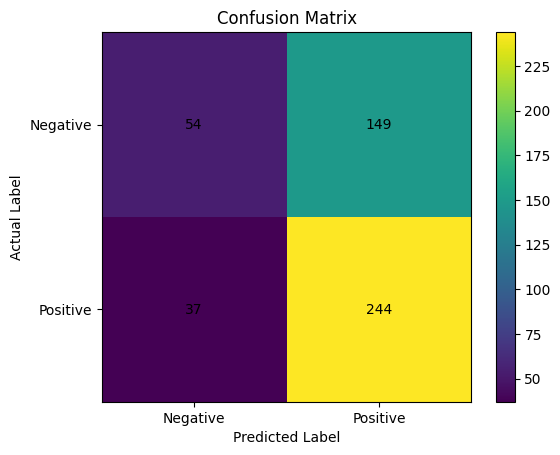

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure()
plt.imshow(cm)

plt.title("Confusion Matrix")
plt.colorbar()

labels = ['Negative', 'Positive']
plt.xticks(np.arange(len(labels)), labels)
plt.yticks(np.arange(len(labels)), labels)

# Add values inside matrix
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

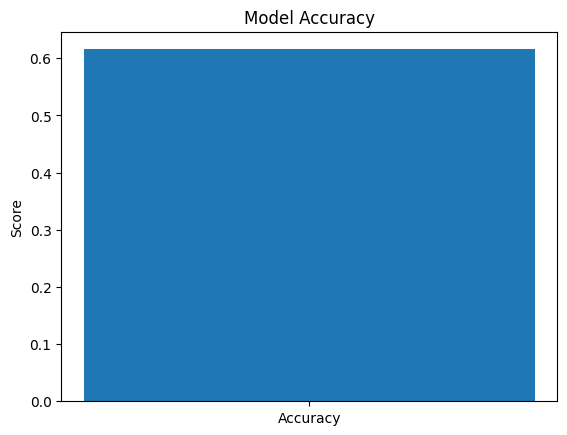

In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

plt.figure()
plt.bar(['Accuracy'], [accuracy])

plt.title("Model Accuracy")
plt.ylabel("Score")

plt.show()

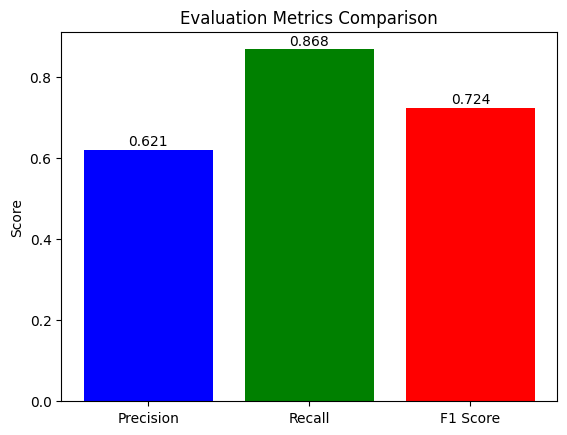

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

metrics_names = ['Precision', 'Recall', 'F1 Score']
values = [precision, recall, f1]

plt.figure()

# 🎨 Custom colors
colors = ['blue', 'green', 'red']

plt.bar(metrics_names, values, color=colors)

plt.title("Evaluation Metrics Comparison")
plt.ylabel("Score")

# Show values on top of bars
for i, v in enumerate(values):
    plt.text(i, v + 0.01, str(round(v, 3)), ha='center')

plt.show()





# from sklearn.metrics import precision_score, recall_score, f1_score

# precision = precision_score(y_test, y_pred)
# recall = recall_score(y_test, y_pred)
# f1 = f1_score(y_test, y_pred)

# metrics_names = ['Precision', 'Recall', 'F1 Score']
# values = [precision, recall, f1]
# colors = ['blue', 'green', 'red']
# plt.figure()
# plt.bar(metrics_names, values)

# plt.title("Evaluation Metrics Comparison")
# plt.ylabel("Score")

# plt.show()

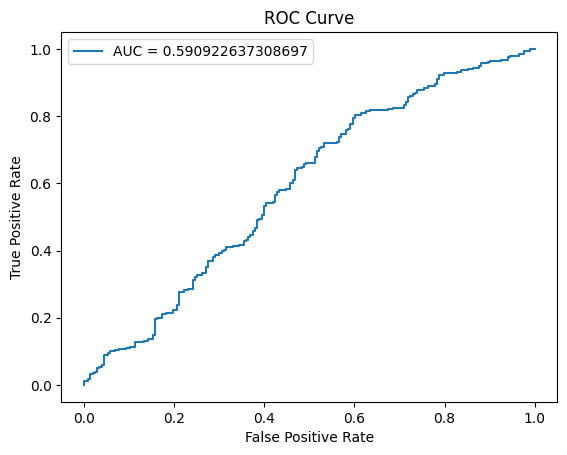

In [ ]:
from sklearn.metrics import roc_curve, auc

y_prob = gnb.predict_proba(X_test)[:, 1]

fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, label="AUC = " + str(roc_auc))

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()

plt.show()

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving test_data_2.csv to test_data_2.csv


In [ ]:
#NOW USING TEST DATASET
print("\n\n \n NOW USING TEST DATASET")
DF_test = pd.read_csv("test_data_2.csv") #data frame
DF_test



 
 NOW USING TEST DATASET


,date,positive_score,negative_score,neutral_score,overall_sentiment_score,company
0,2019-05-24,0.201491,0.151587,0.646922,0.049903,1
1,2019-05-28,0.164276,0.166477,0.669247,-0.002201,1
2,2019-05-29,0.141757,0.145660,0.712584,-0.003903,1
3,2019-05-30,0.108555,0.267233,0.624212,-0.158677,1
4,2019-05-31,0.225734,0.212640,0.561626,0.013094,1
...,...,...,...,...,...,...
280,2019-12-03,0.144668,0.183632,0.671700,-0.038964,2
281,2019-12-04,0.135863,0.251158,0.612979,-0.115295,2
282,2019-12-05,0.307548,0.134719,0.557733,0.172830,2
283,2019-12-06,0.278567,0.163477,0.557956,0.115091,2


In [ ]:
#print(DF_test.head())
X_test_1 = DF_test.drop('date', axis=1)
#X_test_1  = DF_test
X_test_1
#print(X_test_1.head())
#print(X_test_1.shape)

,positive_score,negative_score,neutral_score,overall_sentiment_score,company
0,0.201491,0.151587,0.646922,0.049903,1
1,0.164276,0.166477,0.669247,-0.002201,1
2,0.141757,0.145660,0.712584,-0.003903,1
3,0.108555,0.267233,0.624212,-0.158677,1
4,0.225734,0.212640,0.561626,0.013094,1
...,...,...,...,...,...
280,0.144668,0.183632,0.671700,-0.038964,2
281,0.135863,0.251158,0.612979,-0.115295,2
282,0.307548,0.134719,0.557733,0.172830,2
283,0.278567,0.163477,0.557956,0.115091,2


In [ ]:
y_pred_2 = gnb.predict(X_test_1)
print(y_pred_2)

[1 1 1 0 1 0 0 0 1 1 0 1 1 1 1 0 1 1 1 1 1 0 0 1 1 0 1 1 0 1 1 1 0 1 0 0 0
 1 1 1 1 0 0 1 1 1 1 0 0 0 0 0 1 1 1 0 0 0 1 0 0 0 0 0 0 1 0 0 0 1 0 1 0 0
 0 1 0 0 1 1 1 1 1 1 1 1 1 0 1 0 0 1 1 0 1 0 1 1 1 1 1 1 1 1 1 1 1 1 0 0 1
 1 1 1 1 1 1 1 1 0 1 1 1 1 1 0 1 0 0 0 1 0 0 1 0 1 0 1 1 1 1 0 1 1 0 1 0 1
 0 0 0 1 1 1 1 1 1 1 1 0 1 1 1 1 1 0 1 1 1 1 0 1 1 0 0 1 0 0 1 1 0 1 0 1 1
 1 1 1 1 1 1 1 1 1 1 0 0 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 0 1 0 0 1 1 1 1 1
 1 1 0 1 1 1 1 1 1 1 0 1 1 0 1 0 1 1 1 1 1 0 1 1 1 1 0 0 1 1 1 1 1 1 1 1 1
 1 1 0 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 0]


In [ ]:
#y_pred_2 = pd.DataFrame(y_pred_2, columns=['close_label_day_5']).to_csv('y_pred_2.csv') RUN ON SHELL